In [1]:
import csv
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import clear_output, display
import time
import copy

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path = "/content/drive/MyDrive/Data/"

num_2 = pd.read_csv(path + "all2.csv")

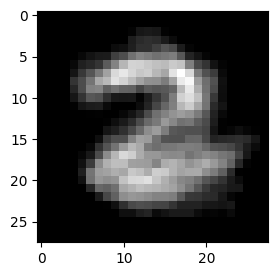

In [4]:
#Generalize pattern for some possible ways to hand write number 2
gen_2 = None #Generalized pattern for handwritten diget 2
for i in range (len(num_2)):
  clear_output(wait = True)
  if i > 10:
    break

  t1 = num_2.iloc[i, 1:] #taking the data for each handwritten two(from each row) and we are selecting from the first row and onward since index 0 is the lable and from index 1 and onward is the data for the image of the number
  t1 = np.array(t1) # then convert that to an array
  t2 = t1.reshape(28,28) #reshaping the array
  if i == 0:
    gen_2 = t2
  else:
    gen_2 = gen_2 + t2

  fig = plt.figure(figsize=(3,3)) #plot the figure/image
  plt.imshow(gen_2, cmap="gray")
  time.sleep(1)
  plt.show()

Generalized patteren for all the samples of Handwritten digits that Represent 2 


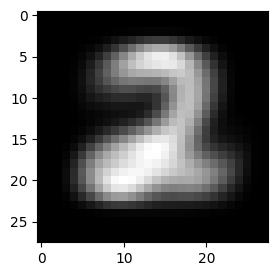

In [5]:
#Generalize all possible patterns to hand write number 2
gen_all_2 = None #Generalized pattern for handwritten diget 2
for i in range (len(num_2)):

  t1 = num_2.iloc[i, 1:] #taking the data for each handwritten two(from each row) and we are selecting from the first row and onward since index 0 is the lable and from index 1 and onward is the data for the image of the number
  t1 = np.array(t1) # then convert that to an array
  t2 = t1.reshape(28,28) #reshaping the array
  if i == 0:
    gen_all_2 = t2
  else:
    gen_all_2 = gen_all_2 + t2

print('Generalized patteren for all the samples of Handwritten digits that Represent 2 ')
fig = plt.figure(figsize=(3,3)) #plot the figure/image
plt.imshow(gen_all_2, cmap="gray")
plt.show()

In [6]:
X = copy.deepcopy(gen_all_2)
Y = copy.deepcopy(gen_all_2)
Z = copy.deepcopy(gen_all_2)

for i in range (len(t2)):
  for j in range (len(X[i])):
    if t2[i][j] >= 0:
      X[i][j]= i
      Y[i][j]= j


%matplotlib notebook

fig = plt.figure()
ax = plt.axes(projection = '3d')
ax.scatter(X,Y,Z, c=Z, cmap = 'viridis', linewidth=0.5)

<IPython.core.display.Javascript object>

In [7]:
np.max(Z)

np.int64(1049539)

Normalization Formula
  - Normalizaation means to convert all data into the same form (like how you convert cm to inches when comparing that mesurment to a dataset of mesuments in inches)

X' = (X - Xmin) / (Xmax - Xmin)

In [8]:
Z = Z/np.max(Z)

In [9]:
#Generalized Surface plot with normalization
import plotly.graph_objects as go
fig = go.Figure(data=[go.Surface(z=Z, x=X, y=Y, colorscale = 'Plasma')])
fig.update_layout(
    title='Surface Plot for the data representation of 2',
    scene = dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z'
    )
)

fig.show()

In [10]:
#Probability Densities: (dot/scatter plot 2D)
print('Probability Density points for values greater than 0.6')
y, x = np.where(Z > 0.6)
plt.figure(figsize = (3,3))
plt.plot(x, -y, 'ro')
plt.show()

Probability Density points for values greater than 0.6


<IPython.core.display.Javascript object>

In [11]:
print(len(y))
print(len(x))

128
128


In [12]:
def comparing_pixel_points (num, x,y,u,v):
  ct = 0
  for i in range (len(y)):
    yaxis = y[i]
    xaxis = x[i]

    for j in range(len(v)):
      vaxis = v[j]
      uaxis = u[j]

      if ((yaxis == vaxis) and (xaxis == uaxis)):
        ct += 1
  print('Number of matches for the number', num, 'is:', ct, '& probability density is', round((ct/len(y))*100), '%')
  return ct

In [13]:
for i in range (10):
#  print(path + "all" + str(i) + ".csv")
  t1 = pd.read_csv(path + "all" + str(i) + ".csv")
  num = t1.iloc[1,0]
  t1 = t1.iloc[1,1:]
  t1 = np.array(t1)
  t1_max= float(t1.max())
  t1 = t1/t1_max
  t1shape = t1.reshape(28,28)
  v, u = np.where(t1shape > 0.25) #Select all pixel values greater than 0.25

  ct = comparing_pixel_points (num, x,y,u,v)

  plt.figure(figsize = (1,1))
  plt.axis('off')
  plt.imshow(t1shape, cmap='gray')
  plt.show()

  #Doesn’t plot

  plt.figure(figsize = (8,3)) #fig size of all the three plots in one row
  #plot 1
  plt.subplot(1, 3, 1)
  plt.plot(x, -y, 'ro')
  plt.title('Ground-Truth')
  plt.xlabel(str(len(y))+ 'pts')

  #plot 2
  plt.subplot(1, 3, 1)
  plt.plot(u, -v, '.b')
  plt.title('Test Number')
  plt.xlabel(str(len(v))+ 'pts')

  #plot 3 (comparasen)
  plt.subplot(1, 3, 3)
  plt.plot(x, -y, 'ro')
  plt.plot(u, -v, '.b')
  plt.title('OverLap-PD')
  plt.xlabel(str(ct)+ '/' + str(len(y)) + '=' + str(round(ct/len(y),2)*100) + '%')

  plt.tight_layout()
  plt.show()
  print('\n\n')

Number of matches for the number 0 is: 84 & probability density is 66 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>




Number of matches for the number 1 is: 25 & probability density is 20 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (21 outputs left out)




Number of matches for the number 9 is: 52 & probability density is 41 %


/tmp/ipykernel_894/1362425206.py:14: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>